In [1]:
import phase_field_data_process_lib as pfdp
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
cwd = os.getcwd()
print("Current working directory: {0}".format(cwd))

# Set xrange of surface:
mesh_range = np.arange(-7e-5, 7e-5, 0.25e-6) # Original
#mesh_range = np.arange(-7e-5, 7e-5, 0.2e-6)
#xgap_spec = 0.4e-6 #double the gap in mesh_range
#xgap_spec = 0.2e-6 #double the gap in mesh_range
xgap_spec = 0.1e-6 #double the gap in mesh_range


Current working directory: /glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode


In [4]:
#data_dir =r'C:\Users\vanan\OneDrive\Desktop\Pit Propagation Model\Single Pit Growth'
data_dir = '/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/data'
processed_data_dir = 'processed_data'
try:
    os.makedirs(data_dir)
except OSError:
    pass
os.chdir(data_dir)
is_dir_exist = os.path.isdir(processed_data_dir) # Check the processed_data folder:
print(is_dir_exist)
if not is_dir_exist:
    os.makedirs(processed_data_dir)
    print("Processed_data folder is created")
else:
    print('Processed_data folder is already existed')


True
Processed_data folder is already existed


In [5]:
os.chdir(processed_data_dir)
cwd = os.getcwd()
print("Current working directory: {0}".format(cwd))


Current working directory: /glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/data/processed_data


In [6]:
## Split data into sub dataset based on simulating time from data_all.txt
#main_data ='../data_all.txt'
#main_data = '../std2_result_rpit_1_1E-5_rpit_2_1E-5_theta_1_0.261799387799149_theta_2_0.523598775598299_I_apply_1E-4_dummy_1.txt'
main_data = '../std2_result_rpit_2E-6_theta_0.261799387799149_I_apply_1E-4_stepzone_0.6_dummy_1.txt'
#main_data = '/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/bng_backup/comsol_batch/dpit_2mics/std2_smallcurr_results1/std2_result_rpit_1_6E-6_rpit_2_8E-6_theta_1_0.261799387799149_theta_2_0.261799387799149_I_apply_1.75E-5_dummy_1.txt'
#main_data = '/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/bng_backup/comsol_batch/dpit_2mics/std2_smallcurr_results1/std2_result_rpit_1_4E-6_rpit_2_4E-6_theta_1_0.261799387799149_theta_2_1.0471975511966_I_apply_1E-5_dummy_1.txt'
vars_list= ['x', 'y', 'cMe', 'phil', 'phipf','phis','I','iloc','t']
data_file_list = os.listdir()
if len(data_file_list)==0:
    print('There is no data file in this folder, Create the subdata from data_all.txt')
    pfdp.data_all_split_file(filename=main_data, vars=vars_list)
    data_file_list = os.listdir()
    print('List of files:',data_file_list)
else:
    print('There is data file in this folder. Here is the list:')
    print(data_file_list)

There is no data file in this folder, Create the subdata from data_all.txt


FileNotFoundError: [Errno 2] No such file or directory: 'std2_result_rpit_2E-6_theta_0.261799387799149_I_apply_1E-4_stepzone_0.6_dummy_1.txt'

In [6]:
### Check if the dataset along the pit surface is existed, if not, create the dataset:

#data_file_list = ['data_1p2s.txt']

phipf_val = -0.15
#phipf_val = -0.25
#phipf_val = -0.5
#phipf_val = 0.0
xgap_spec = 0.02e-6
#xgap_spec = 0.05e-6
#mesh_range = np.arange(-7e-5, 7e-5, 0.2e-6) # test
mesh_range = np.arange(-7.01e-5, 7.01e-5, 0.2e-6) # test

file_surf_name = processed_data_dir+'/'+'data_along_pit_surface.csv'
if os.path.isfile(file_surf_name):
    print(file_surf_name,' is already existed.')
    df_surf = pd.read_csv('../processed_data/data_along_pit_surface.csv') #If df is already exist, load the datafile
else:
    print(file_surf_name, ' is not existed.')
    #df_surf= pfdp.get_data_along_pit_surface(file_list=data_file_list,vars=vars_list,mesh=mesh_range,
    #                                        phipf_threshold = phipf_val, xgap_val = xgap_spec, # original
    #                                         progress_update=True,export_file ='data_along_pit_surface.csv')
    df_surf= pfdp.get_data_along_pit_surface(file_list=data_file_list,vars=vars_list,mesh=mesh_range,
                                            phipf_threshold = phipf_val, xgap_val = xgap_spec, # original
                                             progress_update=True,export_file ='data_along_pit_surface.csv')
    print(file_surf_name,'is created.')

processed_data/data_along_pit_surface.csv  is not existed.
new


/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode/phase_field_data_process_lib.py:103: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df_surf_all = df_surf_all.append(df_line.iloc[i,:])
/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode/phase_field_data_process_lib.py:104: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df_surf_all = df_surf_all.append(df_line.iloc[i+1, :])
/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode/phase_field_data_process_lib.py:103: FutureWarning: The frame.append method is deprecat

Finish processing file: data_3p04s.txt time: 3.04


/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode/phase_field_data_process_lib.py:103: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df_surf_all = df_surf_all.append(df_line.iloc[i,:])
/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode/phase_field_data_process_lib.py:104: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df_surf_all = df_surf_all.append(df_line.iloc[i+1, :])
/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode/phase_field_data_process_lib.py:103: FutureWarning: The frame.append method is deprecat

Finish processing file: data_3p21s.txt time: 3.21


/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode/phase_field_data_process_lib.py:103: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df_surf_all = df_surf_all.append(df_line.iloc[i,:])
/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode/phase_field_data_process_lib.py:104: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df_surf_all = df_surf_all.append(df_line.iloc[i+1, :])
/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode/phase_field_data_process_lib.py:103: FutureWarning: The frame.append method is deprecat

... (93 outputs left out)

/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode/phase_field_data_process_lib.py:103: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df_surf_all = df_surf_all.append(df_line.iloc[i,:])
/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode/phase_field_data_process_lib.py:104: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df_surf_all = df_surf_all.append(df_line.iloc[i+1, :])
/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode/phase_field_data_process_lib.py:103: FutureWarning: The frame.append method is deprecat

Finish processing file: data_2p74s.txt time: 2.74


/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode/phase_field_data_process_lib.py:103: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df_surf_all = df_surf_all.append(df_line.iloc[i,:])
/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode/phase_field_data_process_lib.py:104: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df_surf_all = df_surf_all.append(df_line.iloc[i+1, :])
/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode/phase_field_data_process_lib.py:103: FutureWarning: The frame.append method is deprecat

Finish processing file: data_2p61s.txt time: 2.61
processed_data/data_along_pit_surface.csv is created.


In [16]:

mesh_range = np.arange(-7.01e-5, 7.01e-5, 0.2e-6) # test
#mesh_range = [10,20,30,30,40,20,50]
print(mesh_range)
#print(list(enumerate(mesh_range)))
#print(data_file_list)

[-7.01e-05 -6.99e-05 -6.97e-05 -6.95e-05 -6.93e-05 -6.91e-05 -6.89e-05
 -6.87e-05 -6.85e-05 -6.83e-05 -6.81e-05 -6.79e-05 -6.77e-05 -6.75e-05
 -6.73e-05 -6.71e-05 -6.69e-05 -6.67e-05 -6.65e-05 -6.63e-05 -6.61e-05
 -6.59e-05 -6.57e-05 -6.55e-05 -6.53e-05 -6.51e-05 -6.49e-05 -6.47e-05
 -6.45e-05 -6.43e-05 -6.41e-05 -6.39e-05 -6.37e-05 -6.35e-05 -6.33e-05
 -6.31e-05 -6.29e-05 -6.27e-05 -6.25e-05 -6.23e-05 -6.21e-05 -6.19e-05
 -6.17e-05 -6.15e-05 -6.13e-05 -6.11e-05 -6.09e-05 -6.07e-05 -6.05e-05
 -6.03e-05 -6.01e-05 -5.99e-05 -5.97e-05 -5.95e-05 -5.93e-05 -5.91e-05
 -5.89e-05 -5.87e-05 -5.85e-05 -5.83e-05 -5.81e-05 -5.79e-05 -5.77e-05
 -5.75e-05 -5.73e-05 -5.71e-05 -5.69e-05 -5.67e-05 -5.65e-05 -5.63e-05
 -5.61e-05 -5.59e-05 -5.57e-05 -5.55e-05 -5.53e-05 -5.51e-05 -5.49e-05
 -5.47e-05 -5.45e-05 -5.43e-05 -5.41e-05 -5.39e-05 -5.37e-05 -5.35e-05
 -5.33e-05 -5.31e-05 -5.29e-05 -5.27e-05 -5.25e-05 -5.23e-05 -5.21e-05
 -5.19e-05 -5.17e-05 -5.15e-05 -5.13e-05 -5.11e-05 -5.09e-05 -5.07e-05
 -5.05

In [8]:
# print(df_surf)
def read_data_file(file,variable_list):
    #print(variable_list)
    df = pd.read_csv(file, sep="\t", header=None)
    #print(variable_list)
    df.columns = variable_list
    return df

df = read_data_file('data_0s.txt',vars_list)
df.to_csv('raw0.csv')

In [7]:

ymesh = np.arange(-4.99e-5, 0, 0.2e-6) 
print(ymesh)

[-4.99e-05 -4.97e-05 -4.95e-05 -4.93e-05 -4.91e-05 -4.89e-05 -4.87e-05
 -4.85e-05 -4.83e-05 -4.81e-05 -4.79e-05 -4.77e-05 -4.75e-05 -4.73e-05
 -4.71e-05 -4.69e-05 -4.67e-05 -4.65e-05 -4.63e-05 -4.61e-05 -4.59e-05
 -4.57e-05 -4.55e-05 -4.53e-05 -4.51e-05 -4.49e-05 -4.47e-05 -4.45e-05
 -4.43e-05 -4.41e-05 -4.39e-05 -4.37e-05 -4.35e-05 -4.33e-05 -4.31e-05
 -4.29e-05 -4.27e-05 -4.25e-05 -4.23e-05 -4.21e-05 -4.19e-05 -4.17e-05
 -4.15e-05 -4.13e-05 -4.11e-05 -4.09e-05 -4.07e-05 -4.05e-05 -4.03e-05
 -4.01e-05 -3.99e-05 -3.97e-05 -3.95e-05 -3.93e-05 -3.91e-05 -3.89e-05
 -3.87e-05 -3.85e-05 -3.83e-05 -3.81e-05 -3.79e-05 -3.77e-05 -3.75e-05
 -3.73e-05 -3.71e-05 -3.69e-05 -3.67e-05 -3.65e-05 -3.63e-05 -3.61e-05
 -3.59e-05 -3.57e-05 -3.55e-05 -3.53e-05 -3.51e-05 -3.49e-05 -3.47e-05
 -3.45e-05 -3.43e-05 -3.41e-05 -3.39e-05 -3.37e-05 -3.35e-05 -3.33e-05
 -3.31e-05 -3.29e-05 -3.27e-05 -3.25e-05 -3.23e-05 -3.21e-05 -3.19e-05
 -3.17e-05 -3.15e-05 -3.13e-05 -3.11e-05 -3.09e-05 -3.07e-05 -3.05e-05
 -3.03

In [18]:
a = 'a_b_c_d_e_f_g_123.txt'
x = a.split('_')
x = x[2:-2]
print(x)
sen = str(x[0])
for i in range(1,len(x)):
	sen = sen + '_' + str(x[i])
print(sen)

['c', 'd', 'e', 'f']
['c_d', 'c_e', 'c_f']


In [ ]:


print('Processed data after rearranged based on the nearest neighbor')
plot2 = plt.figure(2) #plot of the processed data after rearranged based on the nearest neighbor
plt.plot(df.x,df.y)

plt3=plt.figure(3) #plot of local c.d vs pit length
plt.plot(df['l_accum'],df['iloc'])

plt.show()
#print(l_dict)

In [16]:
x = 'rpit_1_4E-6_rpit_2_1E-5_theta_1_0.785398163397448_theta_2_0.523598775598299_I_apply_7.5E-5'
y = x.split('_')
float(y[2][0])
num = float(y[5][0])*10**(-1*float(y[5][-1]))
num = float(y[11])
print(num)

0.523598775598299


In [18]:
a = [(3,5),(8,9),(3,10)]
sorted_by_second = sorted(a, key=lambda tup: tup[0])
print(sorted_by_second)

[(3, 5), (3, 10), (8, 9)]


[0.7273  1.1152  4.9621  4.7035  4.6388  0.40403 1.8264  1.2122  0.1131
 0.      4.0246  1.9234  3.6044  4.4449  3.9276  2.3113  1.7294  0.50101
 2.2143  3.4104  3.1195  2.6022  2.9255  0.82428 2.8285  3.0225  0.63032
 3.3134  2.4083  2.7315  0.21008 2.5053  0.30705 4.2509  4.3155  1.0182
 3.7013  5.      0.92126 4.1216  1.5031  4.8328  1.4062  1.3092  2.1173
 3.5074  3.2164  2.0204  1.6001  3.8306  4.5095 ]


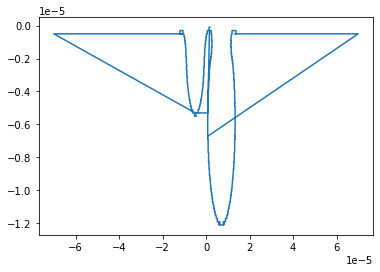

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

vars = ['a','b','c']

#df = pd.DataFrame(columns=vars)
#outDir = '/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/post_test/csvtest'
outDir = '/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/post_test/output/dpit_2mics/dpit_2mics_smallcurrent'
#outFolder = 'rpit_1_4E-6_rpit_2_1E-5_theta_1_0.785398163397448_theta_2_0.523598775598299_I_apply_7.5E-5'
outFolder = 'rpit_1_4E-6_rpit_2_6E-6_theta_1_1.30899693899575_theta_2_0.261799387799149_I_apply_5E-5'
nnFilePath = outDir + '/' + outFolder + '/' + 'all_nn_data.csv'
#nnFilePath = outDir + '/' + 'org_1.csv'

df = pd.read_csv(nnFilePath) 

t = df['t'].unique()
print(t)

df_t = df[df['t']==0.7273] # original
#print(df['x'])
#print(df['x'][42322])

plt.plot(df_t['x'],df_t['y'])

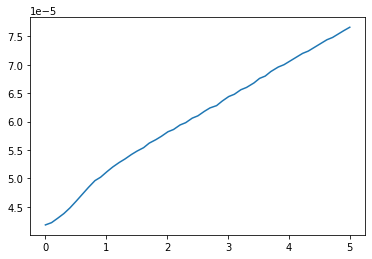

In [39]:

#outDir = '/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/post_test/csvtest'
#outDir = '/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/post_test/output/dpit_2mics/std2_results_largeconc'
#outDir = '/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/post_test/output/dpit_2mics/std2_smallcurr_results2'
outDir = '/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/post_test/output/dpit_2mics/dpit_2mics_smallcurrent'
#outDir = '/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/post_test/output/dpit_5mics/dpit_5mics_2em6/'
#outDir = '/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/post_test/temp/test_out'
#outFolder = 'rpit_1_4E-6_rpit_2_1E-5_theta_1_0.785398163397448_theta_2_0.523598775598299_I_apply_7.5E-5'
#outFolder = 'rpit_1_2E-6_rpit_2_2E-6_theta_1_0.261799387799149_theta_2_1.30899693899575_I_apply_1E-4'
#outFolder = 'rpit_1_2E-6_rpit_2_4E-6_theta_1_0.785398163397448_theta_2_0.261799387799149_I_apply_1E-4'
#outFolder = 'rpit_1_2E-6_rpit_2_6E-6_theta_1_1.30899693899575_theta_2_0.261799387799149_I_apply_7.5E-5'
#outFolder = 'rpit_1_8E-6_rpit_2_8E-6_theta_1_0.261799387799149_theta_2_1.0471975511966_I_apply_1E-4'
#outFolder2 = 'rpit_1_8E-6_rpit_2_8E-6_theta_1_0.261799387799149_theta_2_0.523598775598299_I_apply_7.5E-5'
#outFolder = 'rpit_1_8E-6_rpit_2_8E-6_theta_1_0.261799387799149_theta_2_0.523598775598299_I_apply_7.5E-6'
#outFolder2 = 'rpit_1_8E-6_rpit_2_8E-6_theta_1_0.261799387799149_theta_2_0.523598775598299_I_apply_9E-6'

#outFolder = 'rpit_1_4E-6_rpit_2_4E-6_theta_1_0.261799387799149_theta_2_1.0471975511966_I_apply_2.5E-6'
#outFolder2 = 'rpit_1_4E-6_rpit_2_4E-6_theta_1_0.261799387799149_theta_2_1.0471975511966_I_apply_9E-6'

#outFolder = 'rpit_1_2E-6_rpit_2_6E-6_theta_1_1.30899693899575_theta_2_0.261799387799149_I_apply_1E-5_stepzone_0.25'
#outFolder2 = 'rpit_1_2E-6_rpit_2_6E-6_theta_1_1.30899693899575_theta_2_0.261799387799149_I_apply_1.75E-5_stepzone_0.25'

#outFolder = 'rpit_1_4E-6_rpit_2_6E-6_theta_1_1.30899693899575_theta_2_0.261799387799149_I_apply_5E-5'

## rapidtest
outFolder = 'rpit_1_1E-5_rpit_2_1E-5_theta_1_1.0471975511966_theta_2_1.30899693899575_I_apply_7.5E-5'

nnFilePath = outDir + '/' + outFolder + '/' + 'depth_time.csv'
#nnFilePath2 = outDir + '/' + outFolder2 + '/' + 'depth_time.csv'

df = pd.read_csv(nnFilePath) 
#df2 = pd.read_csv(nnFilePath2) 

#plt.plot(df['t'],df['max depth'])
#plt.plot(df2['t'],df2['max depth'])
plt.plot(df['t'],df['max width'])

In [15]:
df['t']
idx = df.index[df['t'] < 2]
print(idx)
#print(df['t'])
n = df['t'].loc[idx]
nList = n.to_list()
print(nList)

Int64Index([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,
            19],
           dtype='int64')
[0.0, 0.10212, 0.20437, 0.30661, 0.40886, 0.51111, 0.61336, 0.7156, 0.81785, 0.9201, 1.0223, 1.1246, 1.2013, 1.3035, 1.4058, 1.508, 1.6103, 1.7125, 1.8148, 1.917]


In [4]:
import itertools as it
a = [25,50]
b = [25,0.5]

z = list(it.product(a,b))
c = list(it.combinations_with_replacement(a,2))

print(z)
print(c)

[(25, 25), (25, 0.5), (50, 25), (50, 0.5)]
[(25, 25), (25, 50), (50, 50)]


In [44]:
import pandas as pd

df = pd.DataFrame([[1,'a'],[2,'b'],[3,'c'],[4,'d']],columns=['num','alpha'])
print(df)
print(df['num'][0])
#print(df.iloc[0,1])
#df2 = df.loc[df['num']==2]
#print(df2)
df = df.drop([0])
print(df)
print(df['num'][1])
#print(df.iloc[0,1])
#ind1 = df[df['num'] >= 3].index
#df2 = df.loc[ind1]
#print(df2)

   num alpha
0    1     a
1    2     b
2    3     c
3    4     d
1
   num alpha
1    2     b
2    3     c
3    4     d


KeyError: 0